In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import seaborn as sns
from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

from matplotlib.collections import LineCollection
from matplotlib import colors as mcolors
import scipy
import h5py

**get accurate M2 ROI location**

In [51]:
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"


mice= ['cm229','cm241','cm242','cm126','cm128','cm125']

#
fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"

figure_config_root = str(PREPARES / "config") + "/"

In [52]:
dict_fs_mice = {}
dict_ds_factor_mice = {}
dict_step_1_root_mice = {}
dict_IDX_sorted_mice = {}
dict_M2_ind_mice = {}
dict_S1_ind_mice = {}
dict_node_coords_mice = {}
for mouse_id in mice:
    if mouse_id == 'cm229':
        dict_ds_factor_mice[mouse_id] = 4
        dict_fs_mice[mouse_id] = 15
        dict_step_1_root_mice[mouse_id]=step_1_root
    elif mouse_id in ['cm241','cm242']:
        dict_ds_factor_mice[mouse_id] = 3
        dict_fs_mice[mouse_id] = 20
        dict_step_1_root_mice[mouse_id]=step_1_root
    elif mouse_id in ['cm125','cm126','cm128']:
        dict_ds_factor_mice[mouse_id] = 3
        dict_fs_mice[mouse_id] = 20
        dict_step_1_root_mice[mouse_id]=step_1_root
        
    with h5py.File(dict_step_1_root_mice[mouse_id].replace('step_1','step_0')+mouse_id+'/idx_sorted_500_{}.mat'.format(mouse_id),'r') as f_idx:
        IDX_sorted = np.array(f_idx['IDX_sorted']).T
        IDX_sorted = IDX_sorted.astype(float)
        IDX_sorted[IDX_sorted==0]='nan'
        props = regionprops(IDX_sorted.astype(int))
        node_coords = [props[i].centroid for i in range(len(props))]
        node_coords = np.asarray(node_coords, dtype=np.float32)
    
        dict_node_coords_mice[mouse_id] = node_coords
        dict_IDX_sorted_mice[mouse_id] = IDX_sorted
        
    M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse_id)
    if mouse_id in ['cm125','cm126','cm128']:
        sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse_id)        
    else:
        sensory_ind = load_pickle(fetch_path_S1+'brightest_ind_'+mouse_id)
    if mouse_id == 'cm229':
        sensory_ind['LW']=37  
        sensory_ind['RM']= 475
        sensory_ind['LM'] = 31
        sensory_ind['LV']=106
        sensory_ind['RV']=415
    elif mouse_id in ['cm241','cm242'] :
        p=1
        # sensory_ind['RM']= sensory_ind['mouth']
        # M2_ind['RM']= M2_ind['mouth']
    elif mouse_id in ['cm125','cm126','cm128']:
        extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse_id)
        extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse_id)
        sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
        M2_ind['RM'] = extra_extra_ind['right_mouth_motor']
        if mouse_id == 'cm125':
            sensory_ind['LV']=extra_ind['LV']
            sensory_ind['RV']=extra_ind['RV']
        elif mouse_id == 'cm128':
            sensory_ind['RW'] = extra_extra_ind['right_whisker_sensory']
            M2_ind['RW'] = extra_extra_ind['right_whisker_motor']
    dict_M2_ind_mice[mouse_id] = M2_ind
    dict_S1_ind_mice[mouse_id] = sensory_ind

# load if it has been saved:

In [5]:
save_path_here = figure_config_root
dict_seed_ROI_xy_mice = load_pickle(save_path_here+'dict_seed_ROI_xy_mice')

# from scratch

In [54]:
prefix = '/mnt/staging/'
dict_full_jrgeco_dbsl_mice = load_pickle(str(PREPARES / "epochs-licking/dict_full_jrgeco_mice"))

In [7]:
dict_seed_ROI_xy_mice = {}

In [11]:
mouse_id = 'cm229'

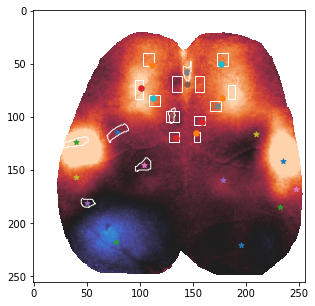

In [17]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 

seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
snapshot_integrated = np.mean(np.mean(dict_full_jrgeco_dbsl_mice[mouse_id][:,:,40:42],-1),-1)
ax.imshow(snapshot_integrated,vmin=-0.03,vmax=0.03,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=30 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=30, zorder=2)

from matplotlib import patches
y_top_left=103;y_botton_right=113;x_top_left=40;x_botton_right=52;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=173;y_botton_right=183;x_top_left=40;x_botton_right=52;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right




y_top_left=130;y_botton_right=140;x_top_left=62;x_botton_right=77;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=152;y_botton_right=160;x_top_left=62;x_botton_right=77;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=125;y_botton_right=137;x_top_left=95;x_botton_right=105;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=151;y_botton_right=161;x_top_left=99;x_botton_right=108;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=109;y_botton_right=119;x_top_left=80;x_botton_right=90;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=95;y_botton_right=103;x_top_left=65;x_botton_right=83;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=183;y_botton_right=190;x_top_left=70;x_botton_right=83;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=166;y_botton_right=176;x_top_left=85;x_botton_right=95;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=151;y_botton_right=157;x_top_left=114;x_botton_right=124;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=127;y_botton_right=137;x_top_left=114;x_botton_right=124;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

from skimage import measure
# plot contours of others
for bdp_here in ['RW','RHP']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==sensory_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')   
        



In [18]:
dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy

# cm242 now

In [140]:
mouse_id = 'cm242'

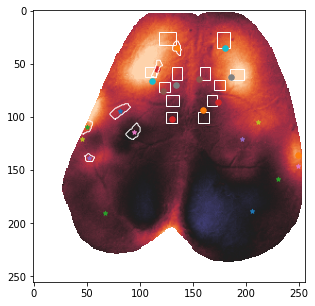

In [150]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
sensory_ind['RM']=sensory_ind['mouth']
sensory_ind['LM']=3
M2_ind['LM']=3
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 

seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
snapshot_integrated = np.mean(np.mean(dict_full_jrgeco_dbsl_mice[mouse_id][:,:,40:42],-1),-1)
ax.imshow(snapshot_integrated,vmin=-0.03,vmax=0.03,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=20 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=30, zorder=2)

from matplotlib import patches
y_top_left=118;y_botton_right=134;x_top_left=20;x_botton_right=32;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=173;y_botton_right=185;x_top_left=20;x_botton_right=35;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right



y_top_left=185;y_botton_right=198;x_top_left=55;x_botton_right=65;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=130;y_botton_right=140;x_top_left=53;x_botton_right=65;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=157;y_botton_right=166;x_top_left=53;x_botton_right=65;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=125;y_botton_right=137;x_top_left=80;x_botton_right=90;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right


y_top_left=105;y_botton_right=115;x_top_left=53;x_botton_right=63;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=118;y_botton_right=128;x_top_left=67;x_botton_right=77;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=163;y_botton_right=173;x_top_left=80;x_botton_right=90;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   

y_top_left=155;y_botton_right=165;x_top_left=96;x_botton_right=106;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   

y_top_left=125;y_botton_right=135;x_top_left=96;x_botton_right=106;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   

y_top_left=170;y_botton_right=180;x_top_left=65;x_botton_right=75;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   


from skimage import measure
# plot contours of others
for bdp_here in ['RFP','RM']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==sensory_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')   
        
        
 



In [151]:
dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy

save

now cm241

In [127]:
mouse_id = 'cm241'




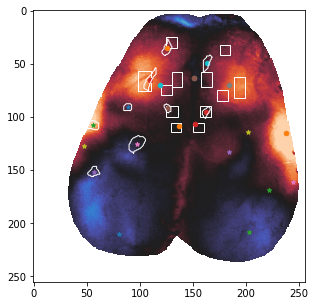

In [128]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
sensory_ind['RM']=sensory_ind['mouth']
sensory_ind['LM']=11
M2_ind['LM']=11
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 

seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
snapshot_integrated = np.mean(np.mean(dict_full_jrgeco_dbsl_mice[mouse_id][:,:,40:42],-1),-1)
ax.imshow(snapshot_integrated,vmin=-0.02,vmax=0.02,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=20 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=20, zorder=2)

from matplotlib import patches
y_top_left=125;y_botton_right=135;x_top_left=25;x_botton_right=35;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=175;y_botton_right=185;x_top_left=32;x_botton_right=42;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right


y_top_left=98;y_botton_right=110;x_top_left=57;x_botton_right=76;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=130;y_botton_right=140;x_top_left=58;x_botton_right=72;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=158;y_botton_right=168;x_top_left=58;x_botton_right=72;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right


y_top_left=125;y_botton_right=136;x_top_left=90;x_botton_right=100;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=189;y_botton_right=199;x_top_left=63;x_botton_right=82;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=157;y_botton_right=167;x_top_left=90;x_botton_right=100;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=173;y_botton_right=183;x_top_left=75;x_botton_right=85;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=120;y_botton_right=130;x_top_left=70;x_botton_right=80;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=150;y_botton_right=160;x_top_left=106;x_botton_right=114;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   

y_top_left=129;y_botton_right=139;x_top_left=106;x_botton_right=114;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right   

from skimage import measure
# plot contours of others
for bdp_here in ['RFP','RM','LFP','RW','LW']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==sensory_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')   
     
    


In [129]:
dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy





cm126

In [92]:
mouse_id = 'cm126'

In [93]:


brain_map_rise = load_pickle(
    prefix+'users/wx2203/new_analysis_locker/pub-locker/aa-pub-vault/Figure-7/brain_map_rise_cm126')



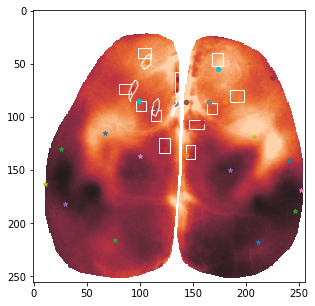

In [105]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 


seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
ax.imshow(brain_map_rise,vmin=-0.045,vmax=0.045,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=20 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=20, zorder=2)

from matplotlib import patches
y_top_left=98;y_botton_right=110;x_top_left=35;x_botton_right=45;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=168;y_botton_right=178;x_top_left=40;x_botton_right=52;

out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right


y_top_left=80;y_botton_right=92;x_top_left=69;x_botton_right=79;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=185;y_botton_right=198;x_top_left=75;x_botton_right=86;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=133;y_botton_right=140;x_top_left=58;x_botton_right=78;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=133;y_botton_right=140;x_top_left=58;x_botton_right=78;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=110;y_botton_right=120;x_top_left=94;x_botton_right=104;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=146;y_botton_right=160;x_top_left=103;x_botton_right=112;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=96;y_botton_right=106;x_top_left=85;x_botton_right=95;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=163;y_botton_right=173;x_top_left=87;x_botton_right=97;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=118;y_botton_right=128;x_top_left=120;x_botton_right=134;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=143;y_botton_right=152;x_top_left=127;x_botton_right=140;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

from skimage import measure
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')




In [106]:


dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy




# cm128

In [107]:
mouse_id = 'cm128'

In [108]:
brain_map_rise = load_pickle(
    prefix+'users/wx2203/new_analysis_locker/pub-locker/aa-pub-vault/Figure-7/brain_map_rise_'+mouse_id)



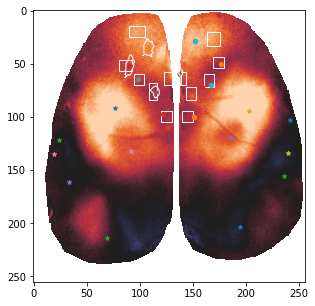

In [123]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 


seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
ax.imshow(brain_map_rise,vmin=-0.03,vmax=0.03,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=20 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=20, zorder=2)

from matplotlib import patches
y_top_left=90;y_botton_right=105;x_top_left=15;x_botton_right=25;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=163;y_botton_right=175;x_top_left=20;x_botton_right=33;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right


y_top_left=80;y_botton_right=93;x_top_left=47;x_botton_right=57;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=169;y_botton_right=179;x_top_left=44;x_botton_right=54;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=123;y_botton_right=130;x_top_left=58;x_botton_right=70;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=137;y_botton_right=143;x_top_left=58;x_botton_right=70;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=109;y_botton_right=116;x_top_left=68;x_botton_right=84;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=143;y_botton_right=153;x_top_left=72;x_botton_right=84;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=94;y_botton_right=104;x_top_left=60;x_botton_right=70;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=160;y_botton_right=170;x_top_left=60;x_botton_right=72;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=140;y_botton_right=150;x_top_left=95;x_botton_right=105;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=120;y_botton_right=130;x_top_left=95;x_botton_right=105;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

from skimage import measure
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')





In [124]:
dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy



# cm125

In [6]:
brain_map_body_trunk = load_pickle(
    prefix+'users/wx2203/new_analysis_locker/pub-locker/aa-pub-vault/Figure-7/brain_map_body_trunk_cm125')



In [7]:
mouse_id = 'cm125'

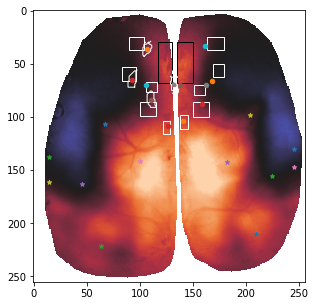

In [45]:
M2_ind = dict_M2_ind_mice[mouse_id]
sensory_ind = dict_S1_ind_mice[mouse_id]
sensory_ind['LM']=sensory_ind['mouth']
M2_ind['LM']=M2_ind['mouth']
node_coords  = dict_node_coords_mice[mouse_id]
IDX_sorted = dict_IDX_sorted_mice[mouse_id] 


seed_ROI_xy = {}
fig,ax = plt.subplots(1,figsize=(5,5))
ax.imshow(brain_map_body_trunk,vmin=-0.08,vmax=0.08,cmap='icefire')

for i_bdp, bdp_S1 in enumerate(['RFP','RM','RW','RHP','LFP','LM','LW','LHP','LN','RN','LV','RV']):
    region_number = sensory_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=20 , zorder=2)
    region_number = M2_ind[bdp_S1]
    ax.scatter(node_coords[region_number,1], node_coords[region_number,0], s=20, zorder=2)

from matplotlib import patches
y_top_left=90;y_botton_right=104;x_top_left=25;x_botton_right=37;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'RFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=163;y_botton_right=179;x_top_left=25;x_botton_right=37;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
ax.grid()
bdp = 'LFP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=83;y_botton_right=96;x_top_left=53;x_botton_right=66;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=169;y_botton_right=179;x_top_left=50;x_botton_right=63;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LM'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=117;y_botton_right=130;x_top_left=30;x_botton_right=68;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='black',facecolor='none')
ax.add_patch(rect)
bdp = 'RHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=135;y_botton_right=150;x_top_left=30;x_botton_right=68;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='black',facecolor='none')
ax.add_patch(rect)
bdp = 'LHP'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=100;y_botton_right=115;x_top_left=86;x_botton_right=99;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=150;y_botton_right=165;x_top_left=86;x_botton_right=100;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LW'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=97+9;y_botton_right=107+9;x_top_left=67;x_botton_right=77;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=159-8;y_botton_right=169-8;x_top_left=70;x_botton_right=80;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LN'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=138;y_botton_right=145;x_top_left=98;x_botton_right=112;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'LV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

y_top_left=122;y_botton_right=128;x_top_left=104;x_botton_right=116;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax.add_patch(rect)
bdp = 'RV'
seed_ROI_xy[bdp]={}
seed_ROI_xy[bdp]['y_top_left']=y_top_left
seed_ROI_xy[bdp]['y_botton_right']=y_botton_right
seed_ROI_xy[bdp]['x_top_left']=x_top_left
seed_ROI_xy[bdp]['x_botton_right']=x_botton_right

from skimage import measure
# plot contours of others
for bdp_here in ['RW','RHP','RFP','RM']:
    bw = IDX_sorted==M2_ind[bdp_here]+1
    contours = measure.find_contours(bw, 0.8)    
    for contour in contours:
        ax.plot(contour[:,1],contour[:,0],linewidth=1,color='white')




In [46]:
dict_seed_ROI_xy_mice[mouse_id] = seed_ROI_xy



In [152]:
save_path_here = figure_config_root
save_pickle(dict_seed_ROI_xy_mice,save_path_here+'dict_seed_ROI_xy_mice')